This is a hand implemented notebook to understand each and everything and never leave a thing as a blackbox.


In [2]:
import hashlib
import math
import pickle
import ssl
import tarfile
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset





SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)


if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print(f"Using device: {DEVICE}")




# 3. Local debug switch (True = tiny fast runs on Mac; False = full 240-epoch run on GPU)
FAST_DEV_RUN = True
# 4. Paths (works whether Jupyter starts in ML-Project/ or ML-Project/notebooks/)
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_ROOT = PROJECT_ROOT / "data"
CKPT_ROOT = PROJECT_ROOT / "checkpoints"
print(f"PyTorch version : {torch.__version__}")
print(f"Using device    : {DEVICE}")
print(f"Project root    : {PROJECT_ROOT}")
print(f"FAST_DEV_RUN    : {FAST_DEV_RUN}")



Using device: mps
PyTorch version : 2.15.0
Using device    : mps
Project root    : /Users/sufyan.siddiqui/ML-Project
FAST_DEV_RUN    : True


In [3]:
CIFAR100_URL = "https://huggingface.co/datasets/nakroy/cifar100-python/resolve/main/cifar-100-python.tar.gz"
CIFAR100_MD5 = "eb9058c3a382ffc7106e4002c42a8d85"


def ensure_cifar100_downloaded(data_root: Path = DATA_ROOT) -> Path:
    cifar_dir = data_root / "cifar-100-python"
    if all((cifar_dir / name).exists() for name in ("train", "test", "meta")):
        print(f"Found existing CIFAR-100 files at: {cifar_dir}")
        return cifar_dir

    data_root.mkdir(parents=True, exist_ok=True)
    tar_path = data_root / "cifar-100-python.tar.gz"

    print("Downloading CIFAR-100 (~161 MB)...")
    try:
        import certifi
        ssl_ctx = ssl.create_default_context(cafile=certifi.where())
    except ImportError:
        ssl_ctx = ssl.create_default_context()

    req = urllib.request.Request(CIFAR100_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, context=ssl_ctx) as resp, tar_path.open("wb") as out:
        out.write(resp.read())

    md5 = hashlib.md5(tar_path.read_bytes()).hexdigest()
    assert md5 == CIFAR100_MD5, f"MD5 mismatch! Expected {CIFAR100_MD5}, got {md5}"

    print("Extracting archive...")
    with tarfile.open(tar_path, "r:gz") as tar:
        tar.extractall(path=data_root)
    print(f"Extracted CIFAR-100 to: {cifar_dir}")
    return cifar_dir


CIFAR_DIR = ensure_cifar100_downloaded()

Found existing CIFAR-100 files at: /Users/sufyan.siddiqui/ML-Project/data/cifar-100-python


In [7]:
def unpickle_file(path: Path) -> dict:
    with path.open("rb") as f:
        return pickle.load(f, encoding="bytes")

raw_train = unpickle_file(CIFAR_DIR / "train")
raw_test = unpickle_file(CIFAR_DIR / "test")
raw_meta = unpickle_file(CIFAR_DIR/ "meta")


for dataset, data in {"train": raw_train, "test": raw_test, "meta": raw_meta}.items():
    print(f"Keys in {dataset} dataset: {list(data.keys())}")
    if b"data" in data:
        print(f"  Number of samples : {len(data[b'data'])}")
        print(f"  Shape of data     : {data[b'data'].shape}")
        print(f"  Array type / dtype: {type(data[b'data'])}, {data[b'data'].dtype}")

Keys in train dataset: [b'filenames', b'batch_label', b'fine_labels', b'coarse_labels', b'data']
  Number of samples : 50000
  Shape of data     : (50000, 3072)
  Array type / dtype: <class 'numpy.ndarray'>, uint8
Keys in test dataset: [b'filenames', b'batch_label', b'fine_labels', b'coarse_labels', b'data']
  Number of samples : 10000
  Shape of data     : (10000, 3072)
  Array type / dtype: <class 'numpy.ndarray'>, uint8
Keys in meta dataset: [b'fine_label_names', b'coarse_label_names']


In [12]:
train_images = raw_train[b"data"].reshape(-1,3,32,32).transpose(0,2,3,1)
print(f"Shape of train images after reshaping and transposing: {train_images.shape}")
train_labels = np.array(raw_train[b"fine_labels"], dtype = np.int64)
train_coarse = np.array(raw_train[b"coarse_labels"], dtype = np.int64)
print(f"Shape of train labels: {train_labels.shape}")
print(f"Shape of train coarse labels: {train_coarse.shape}")
print(f"First 10 train labels: {train_labels[:10]}")
print(f"First 10 train coarse labels: {train_coarse[:10]}")
print(f"Unique train labels: {np.unique(train_labels)}")
print(f"Unique train coarse labels: {np.unique(train_coarse)}")
print(f"Number of unique train labels: {len(np.unique(train_labels))}")
print(f"Number of unique train coarse labels: {len(np.unique(train_coarse))}")
print(f"Number of unique train labels: {len(np.unique(train_labels))}")

Shape of train images after reshaping and transposing: (50000, 32, 32, 3)
Shape of train labels: (50000,)
Shape of train coarse labels: (50000,)
First 10 train labels: [19 29  0 11  1 86 90 28 23 31]
First 10 train coarse labels: [11 15  4 14  1  5 18  3 10 11]
Unique train labels: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95
 96 97 98 99]
Unique train coarse labels: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19]
Number of unique train labels: 100
Number of unique train coarse labels: 20
Number of unique train labels: 100


In [14]:
test_images = raw_test[b"data"].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
test_labels = np.array(raw_test[b"fine_labels"], dtype=np.int64)
test_coarse = np.array(raw_test[b"coarse_labels"], dtype=np.int64)
print(f"Shape of test images after reshaping and transposing: {test_images.shape}")
print(f"Shape of test labels: {test_labels.shape}")
print(f"Shape of test coarse labels: {test_coarse.shape}")
print(f"First 10 test labels: {test_labels[:10]}")
print(f"First 10 test coarse labels: {test_coarse[:10]}")
print(f"Unique test labels: {np.unique(test_labels)}")
print(f"Unique test coarse labels: {np.unique(test_coarse)}")
print(f"Number of unique test labels: {len(np.unique(test_labels))}")
print(f"Number of unique test coarse labels: {len(np.unique(test_coarse))}")


Shape of test images after reshaping and transposing: (10000, 32, 32, 3)
Shape of test labels: (10000,)
Shape of test coarse labels: (10000,)
First 10 test labels: [49 33 72 51 71 92 15 14 23  0]
First 10 test coarse labels: [10 10  0  4 10  2 11  7 10  4]
Unique test labels: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95
 96 97 98 99]
Unique test coarse labels: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19]
Number of unique test labels: 100
Number of unique test coarse labels: 20


In [15]:
fine_names = [x.decode("utf-8") for x in raw_meta[b"fine_label_names"]]
coarse_names = [x.decode("utf-8") for x in raw_meta[b"coarse_label_names"]]
print(f"Number of fine label names: {len(fine_names)}")
print(f"Number of coarse label names: {len(coarse_names)}")
print(f"First 10 fine label names: {fine_names[:10]}")
print(f"First 10 coarse label names: {coarse_names[:10]}")
print(f"Unique fine label names: {np.unique(fine_names)}")
print(f"Unique coarse label names: {np.unique(coarse_names)}")
print(f"Number of unique fine label names: {len(np.unique(fine_names))}")
print(f"Number of unique coarse label names: {len(np.unique(coarse_names))}")
print(f"Number of unique fine label names: {len(np.unique(fine_names))}")

Number of fine label names: 100
Number of coarse label names: 20
First 10 fine label names: ['apple', 'aquarium_fish', 'baby', 'bear', 'beaver', 'bed', 'bee', 'beetle', 'bicycle', 'bottle']
First 10 coarse label names: ['aquatic_mammals', 'fish', 'flowers', 'food_containers', 'fruit_and_vegetables', 'household_electrical_devices', 'household_furniture', 'insects', 'large_carnivores', 'large_man-made_outdoor_things']
Unique fine label names: ['apple' 'aquarium_fish' 'baby' 'bear' 'beaver' 'bed' 'bee' 'beetle'
 'bicycle' 'bottle' 'bowl' 'boy' 'bridge' 'bus' 'butterfly' 'camel' 'can'
 'castle' 'caterpillar' 'cattle' 'chair' 'chimpanzee' 'clock' 'cloud'
 'cockroach' 'couch' 'crab' 'crocodile' 'cup' 'dinosaur' 'dolphin'
 'elephant' 'flatfish' 'forest' 'fox' 'girl' 'hamster' 'house' 'kangaroo'
 'keyboard' 'lamp' 'lawn_mower' 'leopard' 'lion' 'lizard' 'lobster' 'man'
 'maple_tree' 'motorcycle' 'mountain' 'mouse' 'mushroom' 'oak_tree'
 'orange' 'orchid' 'otter' 'palm_tree' 'pear' 'pickup_truck

In [16]:
print(f"train_images : {train_images.shape}, dtype={train_images.dtype}, range=[{train_images.min()}, {train_images.max()}]")
print(f"test_images  : {test_images.shape}, dtype={test_images.dtype}")
print(f"Classes      : {len(fine_names)} fine classes grouped into {len(coarse_names)} superclasses")

train_images : (50000, 32, 32, 3), dtype=uint8, range=[0, 255]
test_images  : (10000, 32, 32, 3), dtype=uint8
Classes      : 100 fine classes grouped into 20 superclasses


Plotting image 1 of 10
Plotting image 2 of 10
Plotting image 3 of 10
Plotting image 4 of 10
Plotting image 5 of 10
Plotting image 6 of 10
Plotting image 7 of 10
Plotting image 8 of 10
Plotting image 9 of 10
Plotting image 10 of 10


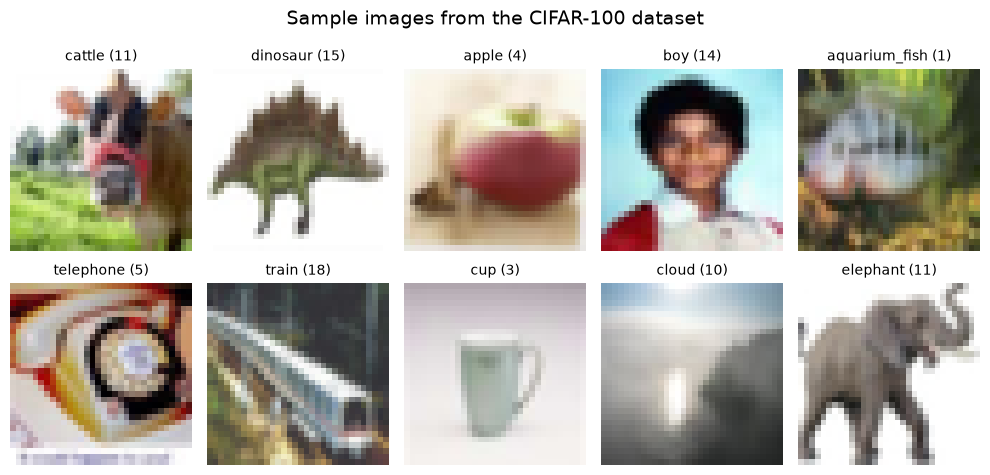

In [18]:
fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(10, 5))
# print(f"figures {fig}, axes {axes}")
for idx, ax in enumerate(axes.flat):
    print(f"Plotting image {idx+1} of 10")
    ax.imshow(train_images[idx])
    ax.set_title(f"{fine_names[train_labels[idx]]} ({train_coarse[idx]})", fontsize=10)
    ax.axis("off")


plt.suptitle("Sample images from the CIFAR-100 dataset", fontsize=14)
plt.tight_layout()
plt.show()

Pipeline


In [19]:
scaled = train_images / 255.0  # shape: (50000, 32, 32, 3)
print("Computed mean :", scaled.mean(axis=(0, 1, 2)).round(4))
print("Computed std  :", scaled.std(axis=(0, 1, 2)).round(4))

Computed mean : [0.5071 0.4865 0.4409]
Computed std  : [0.2673 0.2564 0.2762]


In [43]:
# Exact RGB channel mean and std from the DKD / mdistiller CIFAR-100 recipe
CIFAR100_MEAN = np.array([0.5071, 0.4867, 0.4408], dtype=np.float32)
CIFAR100_STD  = np.array([0.2675, 0.2565, 0.2761], dtype=np.float32)


def preprocess_train(img_hwc: np.ndarray) -> np.ndarray:
    """Raw (32, 32, 3) uint8 -> augmented, normalized (3, 32, 32) float32."""
    # print("Raw (32, 32, 3) uint8 -> augmented, normalized (3, 32, 32) float32.")
    # 1. Pad 4 zeros on top/bottom and left/right -> shape becomes (40, 40, 3)
    padded = np.pad(img_hwc, ((4, 4), (4, 4), (0, 0)), mode="constant", constant_values=0)
    # 2. Pick a random 32x32 window (top and left can each be 0..8)
    top = np.random.randint(0, 9)
    left = np.random.randint(0, 9)
    cropped = padded[top : top + 32, left : left + 32]
    # 3. 50% chance left-right mirror flip
    if np.random.rand() < 0.5:
        cropped = cropped[:, ::-1, :]
    
    # 4. Scale to [0, 1], normalize per RGB channel, and transpose HWC -> CHW
    normed = (cropped.astype(np.float32) / 255.0 - CIFAR100_MEAN) / CIFAR100_STD
    return np.ascontiguousarray(normed.transpose(2, 0, 1))

In [44]:
def preprocess_eval(img_hwc: np.ndarray) -> np.ndarray:
    """Raw (32, 32, 3) uint8 -> clean normalized (3, 32, 32) float32 (no crop, no flip)."""
    normed = (img_hwc.astype(np.float32) / 255.0 - CIFAR100_MEAN) / CIFAR100_STD
    return np.ascontiguousarray(normed.transpose(2, 0, 1))

In [45]:

def unnormalize_for_plot(chw: np.ndarray) -> np.ndarray:
    """Undo normalization and CHW -> HWC just so Matplotlib can display a tensor."""
    hwc = chw.transpose(1, 2, 0) * CIFAR100_STD + CIFAR100_MEAN
    return np.clip(hwc, 0.0, 1.0)

In [46]:
# Sanity check on image 0 ('cattle')
sample_eval = preprocess_eval(train_images[0])
print(f"Output shape : {sample_eval.shape}, dtype={sample_eval.dtype}")
print(f"Value range  : min={sample_eval.min():.2f}, max={sample_eval.max():.2f}, mean={sample_eval.mean():.2f}")


Output shape : (3, 32, 32), dtype=float32
Value range  : min=-1.79, max=2.03, mean=0.24


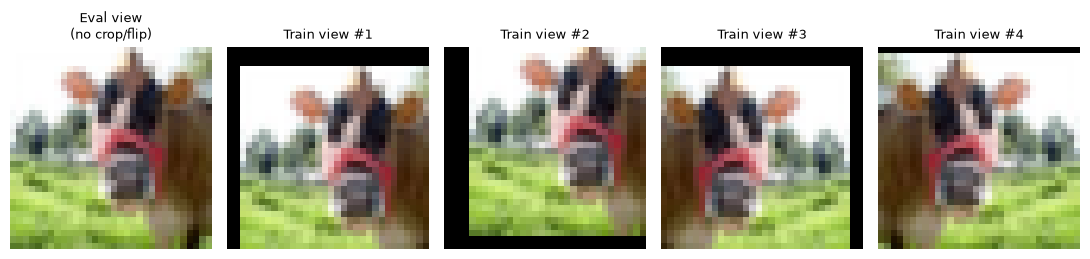

In [47]:
fig, axes = plt.subplots(1, 5, figsize=(11, 2.5))
axes[0].imshow(unnormalize_for_plot(sample_eval))
axes[0].set_title("Eval view\n(no crop/flip)", fontsize=9)
axes[0].axis("off")
for i in range(1, 5):
    aug = preprocess_train(train_images[0])
    axes[i].imshow(unnormalize_for_plot(aug))
    axes[i].set_title(f"Train view #{i}", fontsize=9)
    axes[i].axis("off")
plt.tight_layout()
plt.show()

In [48]:
class SimpleCIFAR100(Dataset):
    def __init__(self, images:np.ndarray, labels: np.ndarray, is_train:bool):
        self.images = images
        self.labels = labels
        self.is_train = is_train

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx: int):
        raw_img = self.images[idx]
        chw = preprocess_train(raw_img) if self.is_train else preprocess_eval(raw_img)
        return torch.from_numpy(chw), int(self.labels[idx])



BATCH_SIZE = 64
train_dataset = SimpleCIFAR100(train_images, train_labels, is_train=True)
test_dataset = SimpleCIFAR100(test_images, test_labels, is_train=False)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

sample_batch_x, sample_batch_y = next(iter(train_loader))
print(f"Train batches per epoch : {len(train_loader)} (50,000 / 64)")
print(f"Test batches            : {len(test_loader)} (10,000 / 128)")
print(f"One batch X shape       : {sample_batch_x.shape}, dtype={sample_batch_x.dtype}")
print(f"One batch Y shape       : {sample_batch_y.shape}, dtype={sample_batch_y.dtype}")

Train batches per epoch : 782 (50,000 / 64)
Test batches            : 157 (10,000 / 128)
One batch X shape       : torch.Size([64, 3, 32, 32]), dtype=torch.float32
One batch Y shape       : torch.Size([64]), dtype=torch.int64


In [50]:
TEACHER_TAR_URL = "https://github.com/megvii-research/mdistiller/releases/download/checkpoints/cifar_teachers.tar"
TEACHER_CKPT_PATH = CKPT_ROOT / "cifar_teachers" / "resnet32x4_vanilla" / "ckpt_epoch_240.pth"


def ensure_teacher_ckpt(ckpt_root: Path = CKPT_ROOT) -> Path:
    ckpt_path = ckpt_root / "cifar_teachers" / "resnet32x4_vanilla" / "ckpt_epoch_240.pth"
    if ckpt_path.exists():
        print(f"Found teacher checkpoint at: {ckpt_path}")
        return ckpt_path
    ckpt_root.mkdir(parents=True, exist_ok=True)
    tar_path = ckpt_root / "cifar_teachers.tar"
    print("Downloading cifar_teachers.tar...")
    try:
        import certifi
        ssl_ctx = ssl.create_default_context(cafile=certifi.where())
    except ImportError:
        ssl_ctx = ssl.create_default_context()
    req = urllib.request.Request(TEACHER_TAR_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, context=ssl_ctx) as resp, tar_path.open("wb") as out:
        while chunk := resp.read(1024 * 1024):
            out.write(chunk)
    with tarfile.open(tar_path, "r") as tar:
        members = [m for m in tar.getmembers() if m.name.startswith("cifar_teachers/resnet32x4_vanilla/")]
        tar.extractall(ckpt_root, members=members)
    tar_path.unlink(missing_ok=True)
    return ckpt_path

In [51]:
ckpt_file = ensure_teacher_ckpt()
print(f"Teacher checkpoint file: {ckpt_file}")


Found teacher checkpoint at: /Users/sufyan.siddiqui/ML-Project/checkpoints/cifar_teachers/resnet32x4_vanilla/ckpt_epoch_240.pth
Teacher checkpoint file: /Users/sufyan.siddiqui/ML-Project/checkpoints/cifar_teachers/resnet32x4_vanilla/ckpt_epoch_240.pth


In [52]:
raw_ckpt = torch.load(ckpt_file, map_location="cpu", weights_only=False)

print("Top-level keys in .pth:", list(raw_ckpt.keys()))
print("First 5 keys:", list(raw_ckpt.keys())[:5])
print("Last 5 keys:", list(raw_ckpt.keys())[-5:])

teacher_state = raw_ckpt["model"]

print("Total tensors in model: ", len(teacher_state))

print("\nFirst 12 Parameter Tensors (name -> shape):")
for name, tensor in list(teacher_state.items())[:12]:
    print(f"{name:>35} : {tensor.shape}")



print("\nLast 4 parameter tensors (name -> shape):")
for name, tensor in list(teacher_state.items())[-4:]:
    print(f"  {name:35s} -> {tuple(tensor.shape)}")










Top-level keys in .pth: ['epoch', 'model', 'accuracy', 'optimizer']
First 5 keys: ['epoch', 'model', 'accuracy', 'optimizer']
Last 5 keys: ['epoch', 'model', 'accuracy', 'optimizer']
Total tensors in model:  172

First 12 Parameter Tensors (name -> shape):
                       conv1.weight : torch.Size([32, 3, 3, 3])
                         bn1.weight : torch.Size([32])
                           bn1.bias : torch.Size([32])
                   bn1.running_mean : torch.Size([32])
                    bn1.running_var : torch.Size([32])
              layer1.0.conv1.weight : torch.Size([64, 32, 3, 3])
                layer1.0.bn1.weight : torch.Size([64])
                  layer1.0.bn1.bias : torch.Size([64])
          layer1.0.bn1.running_mean : torch.Size([64])
           layer1.0.bn1.running_var : torch.Size([64])
              layer1.0.conv2.weight : torch.Size([64, 64, 3, 3])
                layer1.0.bn2.weight : torch.Size([64])

Last 4 parameter tensors (name -> shape):
  layer3.4.

In [53]:
class BasicBlock(nn.Module):
     """Two 3x3 conv layers + skip connection: out = ReLU(F(x) + shortcut(x))."""

     def __init__(
        self,
        in_channels: int,
        out_channels: int,
        stride: int = 1,
        downsample: nn.Module | None = None,
     ):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1   = nn.BatchNorm2d(out_channels)
        self.relu  = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2   = nn.BatchNorm2d(out_channels)
        self.downsample = downsample

     def forward(self, x: torch.Tensor) -> torch.Tensor:
        residual = x

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        if self.downsample is not None:
            residual = self.downsample(residual)

        out = out +residual
        out = self.relu(out) # ReLU after residual addition
        return out

# Sanity check 1: Identity shortcut (64 -> 64 channels, 32x32 -> 32x32)

x_same = torch.randn(2, 64, 32, 32)
block_identity = BasicBlock(in_channels=64, out_channels=64, stride=1)
print(f"Output shape of identity block: {block_identity(x_same).shape}")


# Sanity check 2: Downsample shortcut (64 -> 128 channels, 32x32 -> 16x16 via stride=2)
proj = nn.Sequential(
    nn.Conv2d(64, 128, kernel_size=1, stride=2, bias=False),
    nn.BatchNorm2d(128)
)
block_downsample = BasicBlock(in_channels=64, out_channels=128, stride=2, downsample=proj)
print(f"Output shape of downsample block: {block_downsample(x_same).shape}")




Output shape of identity block: torch.Size([2, 64, 32, 32])
Output shape of downsample block: torch.Size([2, 128, 16, 16])
